# nb10 — Model comparison and biological interpretation

**Prepared in advance and intentionally unexecuted. Run this after nb09 finishes.**

This notebook reviews saved outputs only: **it does not train, tune, rescore raw data or load model
checkpoints**. Compare the RNA/ATAC MLP baselines with the integrated
scMKL-style model, separately in MCF7 and T47D.

Questions:
- Does integration improve AUROC, average precision and classification errors?
- Does it improve over the saved RNA and ATAC MLP baselines?
- Were the selected fits converged, and how do validation/test scores compare?
- Which pathway and motif groups were selected? How do they relate to the earlier biological findings?

No conclusions about nb09 are assumed. Tables, figures and the report are created only when you run it.

### Required inputs
The complete nb09 results directory under results/tables/nb09/RUN_ID/.
It already includes nb08 test predictions, configuration and the split handoff, so neither model
weights nor raw RNA/ATAC files are needed. If using the nb09 results ZIP, extract its contents into
that run directory first.

### Optional biological context
Existing nb04 Hallmark GSEA, nb06 pathway summaries and nb07 motif enrichment tables.
Missing context is reported explicitly and does not stop the performance comparison.
This is a lightweight **CPU** notebook; no GPU or sequence-reference download is required.


## How to interpret the review

Use identical test cells, E2-positive labels and saved decision thresholds:
0.5 for MLP probabilities and 0 for group-lasso decision scores. Recompute metrics from the saved
predictions and verify them against nb09's summary before comparing models.

AUROC and average precision use continuous scores. Kernel scores are uncalibrated, so this notebook
does not compare their log loss/Brier scores with MLP probabilities. Error correction is paired by
cell; it reflects the fixed thresholds and is not a significance test.

Validation/test gaps and solver checks concern the integrated model for each cell line. nb09's portable
export does not include the MLP validation predictions, so this notebook does not invent them.

Group norms are **unsigned predictive weights**, not pathway activity, TF binding or causal effects.
Keep group-coverage exclusions and motif aliases; two names may represent the same kernel.
Cross-line overlap describes selection in two separately fitted models, not transfer performance or
repeated-split stability. Absence from a model's eligible groups is distinguished from a zero weight.

Earlier GSEA/ATAC/motif results use the same cohort and are descriptive context, not independent
validation. Both positive/negative NES and all motif directions, matching-QC flags and coordinate
scenarios are retained. Do not select the most favorable enrichment result.

These are single-split, cell-level results. Biological replicate IDs are unavailable, and
library/treatment confounding remains possible. Test results are already known; any test-guided
tuning needs independent confirmation. No confidence intervals or statistical significance claims
are produced here.


In [1]:
import importlib.util
import subprocess
import sys
packages={"numpy":"numpy","pandas":"pandas","matplotlib":"matplotlib","sklearn":"scikit-learn"}
missing=[spec for name,spec in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import os
try:
    import google.colab
    IN_COLAB=True
except ImportError:
    IN_COLAB=False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE=Path("/content/drive/MyDrive/breast-cancer-multiome-estrogen")
else:
    here=Path.cwd()
    BASE=Path(os.environ.get("MULTIOME_PROJECT_ROOT",
              str(here.parent if here.name=="notebooks" else here)))

# Leave blank only if exactly one completed nb09 results folder exists.
# If several runs exist, set the exact folder name to review.
NB09_RUN_ID=""
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
print("Project:",BASE)
print("Available nb09 folders:",[p.name for p in (BASE/"results"/"tables"/"nb09").glob("*") if p.is_dir()])


Mounted at /content/drive
Project: /content/drive/MyDrive/breast-cancer-multiome-estrogen
Available nb09 folders: ['20261012T085524_321769Z', '20261012T113759_726198Z', '20261012T114858_335840Z']


## Embedded review implementation
Defines functions only; no model code or fitting library is imported.

In [3]:
"""nb10: review saved predictions and group weights; no model fitting."""
from pathlib import Path
import hashlib
import json
import shutil
import sys
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve)

LINES=("MCF7","T47D")
MODES=("RNA_ATAC",)

def sha256(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda:f.read(1024*1024),b""):
            h.update(chunk)
    return h.hexdigest()

def json_save(path,value):
    Path(path).write_text(json.dumps(value,indent=2,allow_nan=False)+"\n")

def read_file(path,inputs,sep=","):
    path=Path(path)
    inputs.append({"path":str(path),"sha256":sha256(path),"bytes":path.stat().st_size})
    if path.suffix==".json":
        return json.loads(path.read_text())
    return pd.read_csv(path,sep=sep)

def as_bool(series):
    mapping={"true":True,"false":False,"1":True,"0":False}
    text=series.astype(str).str.lower()
    if not text.isin(mapping).all():
        raise ValueError(f"Invalid boolean values in {series.name}.")
    return text.map(mapping)

def choose_run(base,run_id):
    root=Path(base)/"results"/"tables"/"nb09"
    if run_id:
        chosen=root/run_id
    else:
        candidates=sorted(p for p in root.glob("*") if (p/"metrics_comparison.csv").is_file())
        if len(candidates)!=1:
            names=[p.name for p in candidates]
            raise ValueError(f"Set NB09_RUN_ID to one completed run. Found: {names}. "
                             "Wait for nb09 to finish or extract its results ZIP into its run folder.")
        chosen=candidates[0]
    required=["config.json","nb08_config.json","nb08_handoff.json","metrics_comparison.csv"]
    for line in LINES:
        required.append(f"{line}_splits.csv")
        for mode in MODES:
            required.extend(f"{line}_{mode}_{suffix}" for suffix in
                ("metrics.json","validation_search.csv","validation_predictions.csv",
                 "test_predictions.csv","group_weights.csv"))
        for mode in ("RNA","ATAC"):
            required.extend([f"nb08_{line}_{mode}_predictions.csv",
                             f"{line}_{mode}_group_coverage.csv"])
    missing=[name for name in required if not (chosen/name).is_file()]
    if missing:
        raise FileNotFoundError("nb09 results incomplete:\n"+"\n".join(missing))
    return chosen

def prepare_review(base,run_id,nb09_run_id):
    source=choose_run(base,nb09_run_id)
    out=Path(base)/"results"/"tables"/"nb10"/run_id
    if out.exists():
        raise FileExistsError("Choose a new RUN_ID; existing review will not be overwritten.")
    out.mkdir(parents=True)
    inputs=[]
    handoff=read_file(source/"nb08_handoff.json",inputs)
    if handoff["positive_class"]!="E2":
        raise ValueError("Unexpected positive class.")
    config=read_file(source/"config.json",inputs)
    baseline=read_file(source/"nb08_config.json",inputs)
    json_save(out/"review_config.json",{
        "nb09_run_id":source.name,"nb08_run_id":handoff["run_id"],
        "nb08_learning_rate":baseline["learning_rate"],"nb09_config":config,
        "positive_class":"E2","confidence_intervals":"not estimated",
        "scope":"Fixed-alpha integrated-model review. No fitting, tuning, bootstrap or prediction."})
    json_save(out/"environment.json",{"python":sys.version,
        "packages":{p:importlib.metadata.version(p) for p in
                    ("numpy","pandas","matplotlib","scikit-learn")}})
    print("Reviewing nb09:",source.name)
    print("nb08 run:",handoff["run_id"],"; learning rate:",baseline["learning_rate"])
    return source,out,inputs,handoff

def prediction_frame(path,expected,inputs,score_column,threshold):
    p=read_file(path,inputs)
    required={"cell_id","label_E2",score_column,"predicted_label_E2"}
    if not required.issubset(p.columns) or not p.cell_id.is_unique:
        raise ValueError(f"Invalid prediction table: {path}")
    p["cell_id"]=p.cell_id.astype(str)
    if not set(p.cell_id)==set(expected.cell_id):
        raise ValueError(f"Missing/extra test or validation cells: {path}")
    p=p.set_index("cell_id").loc[expected.cell_id].reset_index()
    if not np.array_equal(p.label_E2.to_numpy(),expected.label_E2.to_numpy()):
        raise ValueError(f"Label mismatch: {path}")
    score=p[score_column].to_numpy(dtype=float)
    if not np.isfinite(score).all():
        raise ValueError("Nonfinite predictions.")
    if score_column=="probability_E2" and ((score<0)|(score>1)).any():
        raise ValueError("MLP probabilities outside [0,1].")
    predicted=(score>=threshold).astype(int)
    if not np.array_equal(predicted,p.predicted_label_E2):
        raise ValueError("Saved classification differs from its stated threshold.")
    p["score"]=score
    p["predicted"]=predicted
    return p

def calculate_metrics(p):
    y=p.label_E2.to_numpy()
    if set(y)!={0,1}:
        raise ValueError("Both classes required.")
    tn,fp,fn,tp=confusion_matrix(y,p.predicted,labels=[0,1]).ravel()
    return {"n_cells":len(p),"E2_prevalence":float(y.mean()),
        "AUROC":float(roc_auc_score(y,p.score)),
        "average_precision":float(average_precision_score(y,p.score)),
        "accuracy":float(accuracy_score(y,p.predicted)),
        "balanced_accuracy":float(balanced_accuracy_score(y,p.predicted)),
        "F1_E2":float(f1_score(y,p.predicted,zero_division=0)),
        "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp),"errors":int(fp+fn)}

def review_predictions(source,out,inputs,handoff):
    saved=read_file(source/"metrics_comparison.csv",inputs)
    predictions,gaps,solver_rows,split_counts={},[],[],[]
    metric_rows=[]
    for line in LINES:
        path=source/f"{line}_splits.csv"
        if sha256(path)!=handoff["manifests"][line]["sha256"]:
            raise ValueError("Split hash differs from nb08 handoff.")
        m=read_file(path,inputs)
        m["cell_id"]=m.cell_id.astype(str)
        if not m.cell_id.is_unique or set(m["split"])!={"train","validation","test"}:
            raise ValueError("Invalid split manifest.")
        if set(m.cell_line)!={line} or not np.array_equal(m.label_E2,(m.treatment=="E2").astype(int)):
            raise ValueError("Invalid split labels.")
        expected=m.loc[m["split"]=="test",["cell_id","label_E2"]].reset_index(drop=True)
        val=m.loc[m["split"]=="validation",["cell_id","label_E2"]].reset_index(drop=True)
        split_counts.append(m.groupby(["cell_line","split","treatment"]).size().rename("cells").reset_index())
        specifications=[("MLP_nb08",mode,f"nb08_{line}_{mode}_predictions.csv","probability_E2",.5)
                        for mode in ("RNA","ATAC")]
        specifications += [("scMKL_style",mode,f"{line}_{mode}_test_predictions.csv","decision_score_E2",0)
                           for mode in MODES]
        for family,mode,filename,column,threshold in specifications:
            p=prediction_frame(source/filename,expected,inputs,column,threshold)
            met=calculate_metrics(p)
            previous=saved[(saved.cell_line==line)&(saved.model==family)&(saved.modality==mode)]
            if len(previous)!=1:
                raise ValueError("Missing/duplicate model in nb09 summary.")
            for key in ("AUROC","average_precision","accuracy","balanced_accuracy","F1_E2"):
                if not np.isclose(met[key],float(previous.iloc[0][key]),atol=1e-7,rtol=0):
                    raise ValueError(f"Saved metric mismatch: {line} {family} {mode} {key}")
            predictions[(line,family,mode)]=p
            metric_rows.append({"cell_line":line,"model":family,"modality":mode,**met})
            if family=="scMKL_style":
                meta=read_file(source/f"{line}_{mode}_metrics.json",inputs)
                vp=prediction_frame(source/f"{line}_{mode}_validation_predictions.csv",val,inputs,column,0)
                vm=calculate_metrics(vp)
                if not np.isclose(vm["AUROC"],meta["validation_AUROC"],atol=1e-7,rtol=0):
                    raise ValueError("Validation AUROC mismatch.")
                search=read_file(source/f"{line}_{mode}_validation_search.csv",inputs)
                search["converged"]=as_bool(search.converged)
                selected=search[np.isclose(search.alpha_ratio,meta["selected_alpha_ratio"])]
                if len(selected)!=1 or not selected.iloc[0]["converged"]:
                    raise ValueError("Selected model was not a unique converged candidate.")
                if not np.isclose(selected.iloc[0]["validation_AUROC"],vm["AUROC"],atol=1e-7,rtol=0):
                    raise ValueError("Selected candidate/validation predictions disagree.")
                winner=search[search.converged].sort_values(
                    ["validation_AUROC","validation_average_precision","selected_groups","alpha_ratio"],
                    ascending=[False,False,True,False]).iloc[0]
                if not np.isclose(winner.alpha_ratio,meta["selected_alpha_ratio"]):
                    raise ValueError("Selected model does not match the recorded validation selection rule.")
                for _,candidate in search.iterrows():
                    solver_rows.append({"cell_line":line,"modality":mode,**candidate.to_dict(),
                        "chosen":bool(np.isclose(candidate.alpha_ratio,meta["selected_alpha_ratio"]))})
                gaps.append({"cell_line":line,"modality":mode,
                    "training_AUROC":meta["training_AUROC"],"validation_AUROC":vm["AUROC"],
                    "test_AUROC":met["AUROC"],
                    "validation_minus_test_AUROC":vm["AUROC"]-met["AUROC"],
                    "training_minus_test_AUROC":meta["training_AUROC"]-met["AUROC"]})
    metrics=pd.DataFrame(metric_rows)
    metrics.to_csv(out/"verified_metrics.csv",index=False)
    pd.concat(split_counts).to_csv(out/"split_counts.csv",index=False)
    gaps=pd.DataFrame(gaps)
    gaps.to_csv(out/"validation_test_gaps.csv",index=False)
    pd.DataFrame(solver_rows).to_csv(out/"solver_review.csv",index=False)
    comparisons=[]
    for line in LINES:
        joint=predictions[(line,"scMKL_style","RNA_ATAC")]
        joint_met=calculate_metrics(joint)
        for family,mode in (("MLP_nb08","RNA"),("MLP_nb08","ATAC")):
            other=predictions[(line,family,mode)]
            other_met=calculate_metrics(other)
            jc=joint.predicted.to_numpy()==joint.label_E2.to_numpy()
            oc=other.predicted.to_numpy()==other.label_E2.to_numpy()
            comparisons.append({"cell_line":line,"reference":family+"_"+mode,
                "AUROC_joint_minus_reference":joint_met["AUROC"]-other_met["AUROC"],
                "AP_joint_minus_reference":joint_met["average_precision"]-other_met["average_precision"],
                "errors_reference_minus_joint":other_met["errors"]-joint_met["errors"],
                "corrected_by_joint":int((jc&~oc).sum()),"new_errors_from_joint":int((~jc&oc).sum()),
                "both_correct":int((jc&oc).sum()),"both_wrong":int((~jc&~oc).sum())})
        errors=pd.DataFrame({"cell_id":joint.cell_id,"label_E2":joint.label_E2})
        for (cl,family,mode),p in predictions.items():
            if cl==line:
                errors[family+"_"+mode+"_correct"]=p.predicted.to_numpy()==p.label_E2.to_numpy()
        errors.to_csv(out/f"{line}_paired_error_audit.csv",index=False)
    differences=pd.DataFrame(comparisons)
    differences.to_csv(out/"integration_comparison.csv",index=False)
    return metrics,gaps,differences,predictions

def performance_plots(metrics,gaps,predictions,out):
    for line in LINES:
        fig,axes=plt.subplots(1,3,figsize=(17,4))
        for (cl,family,mode),p in predictions.items():
            if cl!=line:continue
            label=family+" "+mode
            fpr,tpr,_=roc_curve(p.label_E2,p.score)
            precision,recall,_=precision_recall_curve(p.label_E2,p.score)
            axes[0].plot(fpr,tpr,label=label)
            axes[1].plot(recall,precision,label=label)
        axes[0].plot([0,1],[0,1],"--",color="grey")
        axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title=line+" test ROC")
        axes[1].axhline(float(metrics.loc[metrics.cell_line==line,"E2_prevalence"].iloc[0]),
                       linestyle="--",color="grey")
        axes[1].set(xlabel="Recall",ylabel="Precision",title="Test precision–recall")
        axes[0].legend(fontsize=7)
        g=gaps[gaps.cell_line==line].set_index("modality")
        g[["training_AUROC","validation_AUROC","test_AUROC"]].plot.bar(ax=axes[2])
        axes[2].set(ylim=(0,1.02),ylabel="AUROC",title="Integrated-model generalization gaps")
        axes[2].tick_params(axis="x",rotation=30)
        fig.tight_layout()
        fig.savefig(out/f"{line}_performance.png",dpi=160)
        plt.show()
        plt.close(fig)

def review_groups(source,out,inputs):
    frames,alias_frames=[],[]
    for line in LINES:
        for mode in MODES:
            w=read_file(source/f"{line}_{mode}_group_weights.csv",inputs)
            if not w.group.is_unique:
                raise ValueError("Duplicate group weights.")
            norms=w.coefficient_group_norm.to_numpy(dtype=float)
            if not np.isfinite(norms).all() or (norms<0).any():
                raise ValueError("Invalid group norms.")
            w["selected"]=as_bool(w.selected)
            if not np.array_equal(w.selected,norms>1e-8):
                raise ValueError("Inconsistent group selection flags.")
            w["cell_line"]=line
            w["input_mode"]=mode
            frames.append(w)
            if mode=="RNA_ATAC":
                joint=w.copy()
        coverage=pd.concat([read_file(source/f"{line}_{mode}_group_coverage.csv",inputs)
                            for mode in ("RNA","ATAC")],ignore_index=True)
        coverage["cell_line"]=line
        coverage.to_csv(out/f"{line}_group_coverage.csv",index=False)
        available=coverage[coverage.status.isin(["retained","identical_feature_membership"])].copy()
        aliases=available.merge(joint[["group","coefficient_group_norm","selected"]].rename(
            columns={"group":"representative"}),on="representative",how="left",validate="many_to_one")
        if aliases.coefficient_group_norm.isna().any():
            raise ValueError("Coverage alias points to a missing joint-model group.")
        alias_frames.append(aliases)
        # Display distinct kernel groups, not duplicate motif aliases.
        for modality in ("RNA","ATAC"):
            top=joint[(joint.modality==modality)&joint.selected].nlargest(15,"coefficient_group_norm")
            fig,ax=plt.subplots(figsize=(10,6))
            if len(top):
                top=top.sort_values("coefficient_group_norm")
                labels=top.group.str.replace("HALLMARK_","",regex=False)
                ax.barh(labels,top.coefficient_group_norm)
            else:
                ax.text(.5,.5,"No selected groups",ha="center",va="center",transform=ax.transAxes)
            ax.set(title=f"{line}: joint-model {modality} groups",xlabel="Coefficient block L2 norm")
            fig.tight_layout()
            fig.savefig(out/f"{line}_{modality}_selected_groups.png",dpi=150)
            plt.show()
            plt.close(fig)
    weights=pd.concat(frames,ignore_index=True)
    weights.to_csv(out/"all_model_group_weights.csv",index=False)
    aliases=pd.concat(alias_frames,ignore_index=True)
    aliases.to_csv(out/"joint_group_aliases.csv",index=False)
    weights.pivot(index=["cell_line","group","modality"],columns="input_mode",
                  values="coefficient_group_norm").to_csv(out/"unimodal_joint_group_comparison.csv")
    a,b=[aliases[aliases.cell_line==line][["group","coefficient_group_norm","selected"]].rename(
        columns={"coefficient_group_norm":f"norm_{line}","selected":f"selected_{line}"}) for line in LINES]
    cross=a.merge(b,on="group",how="outer",validate="one_to_one")
    for line in LINES:
        cross[f"represented_{line}"]=cross[f"norm_{line}"].notna()
    cross.to_csv(out/"cross_line_group_selection.csv",index=False)
    return weights,aliases,cross

def biological_context(base,out,inputs,aliases):
    """Attach earlier full-cohort findings descriptively; never use them to select models."""
    statuses=[]
    def optional(path):
        if not path.is_file():
            statuses.append({"file":str(path),"status":"missing_optional_not_interpreted"})
            return None
        result=read_file(path,inputs,sep="\t")
        statuses.append({"file":str(path),"status":"loaded_descriptive_context"})
        return result
    for line in LINES:
        rna=aliases[(aliases.cell_line==line)&(aliases.modality=="RNA")].copy()
        rna["pathway"]=rna.group.str.replace("^RNA::","",regex=True)
        gsea=optional(Path(base)/"results"/"tables"/"nb04"/f"{line}_hallmark_gsea.tsv")
        if gsea is not None:
            gsea=gsea.rename(columns={"Term":"pathway"})
            gsea=gsea.rename(columns={c:"gsea_"+c for c in gsea.columns if c!="pathway"})
            rna=rna.merge(gsea,on="pathway",how="left",validate="many_to_one",indicator="gsea_match")
        rna.to_csv(out/f"{line}_RNA_groups_GSEA_context.csv",index=False)
        pathway=optional(Path(base)/"results"/"tables"/"nb06"/f"{line}_pathway_summary.tsv")
        if pathway is not None:
            # Preserve every scenario and both all-member/leading-edge summaries.
            joined=rna.merge(pathway,on=["cell_line","pathway"],how="left",
                             suffixes=("","_nb06"),validate="one_to_many")
            joined.to_csv(out/f"{line}_RNA_groups_ATAC_pathway_context.csv",index=False)
    motif=optional(Path(base)/"results"/"tables"/"nb07"/"motif_enrichment_all.tsv")
    atac=aliases[aliases.modality=="ATAC"].copy()
    atac["motif_id"]=atac.group.str.split("::",n=1).str[-1].str.split("__",n=1).str[0]
    if motif is not None:
        for column in ("matching_acceptable","priority_candidate"):
            motif[column]=as_bool(motif[column])
        # Keep direction, coordinate hypothesis, scenario and matching QC; no best-q cherry-picking.
        atac=atac.merge(motif,on=["cell_line","motif_id"],how="left",
                        validate="one_to_many",indicator="enrichment_match")
    atac.to_csv(out/"ATAC_groups_motif_enrichment_context.csv",index=False)
    status=pd.DataFrame(statuses)
    status.to_csv(out/"biological_context_availability.csv",index=False)
    return status

def export_review(base,source,out,inputs,metrics,gaps,differences,weights,status):
    provenance=pd.DataFrame(inputs).drop_duplicates("path")
    provenance.to_csv(out/"input_checksums.csv",index=False)
    lines=[
        "# nb10 model comparison and interpretation",
        "",
        f"Reviewed nb09 run: {source.name}",
        "",
        "This report uses saved predictions and coefficients only. No models were fitted or tuned.",
        "",
        "## Test performance",
        "",
        "| Cell line | Model | Inputs | AUROC | Average precision | Balanced accuracy | Errors |",
        "|---|---|---|---:|---:|---:|---:|",
    ]
    for _,row in metrics.iterrows():
        lines.append(f"| {row.cell_line} | {row.model} | {row.modality} | {row.AUROC:.4f} | "
                     f"{row.average_precision:.4f} | {row.balanced_accuracy:.4f} | {int(row.errors)} |")
    lines+=["","## Descriptive integration differences",""]
    for _,row in differences.iterrows():
        lines.append(f"- {row.cell_line}, joint versus {row.reference}: "
                     f"AUROC difference {row.AUROC_joint_minus_reference:+.5f}; "
                     f"AP difference {row.AP_joint_minus_reference:+.5f}; "
                     f"{int(row.corrected_by_joint)} errors corrected and "
                     f"{int(row.new_errors_from_joint)} new errors.")
    lines+=["","These are single-split point differences, not significance tests or estimates of "
            "biological-replicate uncertainty.","","## Selected groups",""]
    for line in LINES:
        for modality in ("RNA","ATAC"):
            selected=weights[(weights.cell_line==line)&(weights.input_mode=="RNA_ATAC")&
                             (weights.modality==modality)&weights.selected]
            names=selected.nlargest(5,"coefficient_group_norm").group.tolist()
            lines.append(f"- {line} {modality}: {len(selected)} selected representative groups. "
                         f"Highest coefficient norms: {', '.join(names) if names else 'none'}.")
    lines+=["","## Interpretation limits","",
        "- Group norms are unsigned predictive weights, not activation, repression or causal importance.",
        "- Aliases sharing a kernel are not independent selected TFs/pathways.",
        "- Earlier GSEA/ATAC/motif outputs use this same cohort and provide descriptive context, not independent validation.",
        "- Missing groups reflect coverage or filtering; missing context files are not negative biological evidence.",
        "- All nb07 matching-QC flags, directions and coordinate scenarios are retained.",
        "- Cross-line overlap is descriptive and does not measure repeat-split stability or transfer performance.",
        "- Test scores have already been inspected; any test-guided tuning requires independent confirmation.",
        "- Biological replicate IDs are unavailable, and treatment/library confounding remains possible.",
        "- No confidence intervals, significance tests, retraining or cross-line transfer were performed.",
        "",
        "## Next decisions",
        "",
        "Review whether joint kernels improve over the RNA and ATAC MLP baselines; inspect solver "
        "status and validation/test gaps before interpreting small differences. Compare selected groups "
        "with all available biological context, preserving negative NES and failed matching flags. "
        "Use predefined additional splits or independent data for robustness; do not tune on this report.",
        "",
        f"Optional biological-context files available: {int((status.status=='loaded_descriptive_context').sum())}"
        f"/{len(status)}.",
    ]
    (out/"comparison_report.md").write_text("\n".join(lines)+"\n")
    exports=Path(base)/"results"/"exports"
    exports.mkdir(parents=True,exist_ok=True)
    archive=shutil.make_archive(str(exports/f"nb10_{out.name}"),"zip",root_dir=out)
    print("Report:",out/"comparison_report.md")
    print("Results archive:",archive)
    return Path(archive)


## Select and verify the completed run
An incomplete or ambiguous input selection stops with a clear message.
All outputs go into a new nb10 directory; earlier results are preserved.


In [4]:
from IPython.display import display
SOURCE, OUTPUT, INPUTS, HANDOFF = prepare_review(BASE,RUN_ID,NB09_RUN_ID)
print("Output directory:",OUTPUT)

_ = (OUTPUT/'model_comparison_source.py').write_text('"""nb10: review saved predictions and group weights; no model fitting."""\nfrom pathlib import Path\nimport hashlib\nimport json\nimport shutil\nimport sys\nimport importlib.metadata\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,\n    balanced_accuracy_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve)\n\nLINES=("MCF7","T47D")\nMODES=("RNA_ATAC",)\n\ndef sha256(path):\n    h=hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for chunk in iter(lambda:f.read(1024*1024),b""):\n            h.update(chunk)\n    return h.hexdigest()\n\ndef json_save(path,value):\n    Path(path).write_text(json.dumps(value,indent=2,allow_nan=False)+"\\n")\n\ndef read_file(path,inputs,sep=","):\n    path=Path(path)\n    inputs.append({"path":str(path),"sha256":sha256(path),"bytes":path.stat().st_size})\n    if path.suffix==".json":\n        return json.loads(path.read_text())\n    return pd.read_csv(path,sep=sep)\n\ndef as_bool(series):\n    mapping={"true":True,"false":False,"1":True,"0":False}\n    text=series.astype(str).str.lower()\n    if not text.isin(mapping).all():\n        raise ValueError(f"Invalid boolean values in {series.name}.")\n    return text.map(mapping)\n\ndef choose_run(base,run_id):\n    root=Path(base)/"results"/"tables"/"nb09"\n    if run_id:\n        chosen=root/run_id\n    else:\n        candidates=sorted(p for p in root.glob("*") if (p/"metrics_comparison.csv").is_file())\n        if len(candidates)!=1:\n            names=[p.name for p in candidates]\n            raise ValueError(f"Set NB09_RUN_ID to one completed run. Found: {names}. "\n                             "Wait for nb09 to finish or extract its results ZIP into its run folder.")\n        chosen=candidates[0]\n    required=["config.json","nb08_config.json","nb08_handoff.json","metrics_comparison.csv"]\n    for line in LINES:\n        required.append(f"{line}_splits.csv")\n        for mode in MODES:\n            required.extend(f"{line}_{mode}_{suffix}" for suffix in\n                ("metrics.json","validation_search.csv","validation_predictions.csv",\n                 "test_predictions.csv","group_weights.csv"))\n        for mode in ("RNA","ATAC"):\n            required.extend([f"nb08_{line}_{mode}_predictions.csv",\n                             f"{line}_{mode}_group_coverage.csv"])\n    missing=[name for name in required if not (chosen/name).is_file()]\n    if missing:\n        raise FileNotFoundError("nb09 results incomplete:\\n"+"\\n".join(missing))\n    return chosen\n\ndef prepare_review(base,run_id,nb09_run_id):\n    source=choose_run(base,nb09_run_id)\n    out=Path(base)/"results"/"tables"/"nb10"/run_id\n    if out.exists():\n        raise FileExistsError("Choose a new RUN_ID; existing review will not be overwritten.")\n    out.mkdir(parents=True)\n    inputs=[]\n    handoff=read_file(source/"nb08_handoff.json",inputs)\n    if handoff["positive_class"]!="E2":\n        raise ValueError("Unexpected positive class.")\n    config=read_file(source/"config.json",inputs)\n    baseline=read_file(source/"nb08_config.json",inputs)\n    json_save(out/"review_config.json",{\n        "nb09_run_id":source.name,"nb08_run_id":handoff["run_id"],\n        "nb08_learning_rate":baseline["learning_rate"],"nb09_config":config,\n        "positive_class":"E2","confidence_intervals":"not estimated",\n        "scope":"Fixed-alpha integrated-model review. No fitting, tuning, bootstrap or prediction."})\n    json_save(out/"environment.json",{"python":sys.version,\n        "packages":{p:importlib.metadata.version(p) for p in\n                    ("numpy","pandas","matplotlib","scikit-learn")}})\n    print("Reviewing nb09:",source.name)\n    print("nb08 run:",handoff["run_id"],"; learning rate:",baseline["learning_rate"])\n    return source,out,inputs,handoff\n\ndef prediction_frame(path,expected,inputs,score_column,threshold):\n    p=read_file(path,inputs)\n    required={"cell_id","label_E2",score_column,"predicted_label_E2"}\n    if not required.issubset(p.columns) or not p.cell_id.is_unique:\n        raise ValueError(f"Invalid prediction table: {path}")\n    p["cell_id"]=p.cell_id.astype(str)\n    if not set(p.cell_id)==set(expected.cell_id):\n        raise ValueError(f"Missing/extra test or validation cells: {path}")\n    p=p.set_index("cell_id").loc[expected.cell_id].reset_index()\n    if not np.array_equal(p.label_E2.to_numpy(),expected.label_E2.to_numpy()):\n        raise ValueError(f"Label mismatch: {path}")\n    score=p[score_column].to_numpy(dtype=float)\n    if not np.isfinite(score).all():\n        raise ValueError("Nonfinite predictions.")\n    if score_column=="probability_E2" and ((score<0)|(score>1)).any():\n        raise ValueError("MLP probabilities outside [0,1].")\n    predicted=(score>=threshold).astype(int)\n    if not np.array_equal(predicted,p.predicted_label_E2):\n        raise ValueError("Saved classification differs from its stated threshold.")\n    p["score"]=score\n    p["predicted"]=predicted\n    return p\n\ndef calculate_metrics(p):\n    y=p.label_E2.to_numpy()\n    if set(y)!={0,1}:\n        raise ValueError("Both classes required.")\n    tn,fp,fn,tp=confusion_matrix(y,p.predicted,labels=[0,1]).ravel()\n    return {"n_cells":len(p),"E2_prevalence":float(y.mean()),\n        "AUROC":float(roc_auc_score(y,p.score)),\n        "average_precision":float(average_precision_score(y,p.score)),\n        "accuracy":float(accuracy_score(y,p.predicted)),\n        "balanced_accuracy":float(balanced_accuracy_score(y,p.predicted)),\n        "F1_E2":float(f1_score(y,p.predicted,zero_division=0)),\n        "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp),"errors":int(fp+fn)}\n\ndef review_predictions(source,out,inputs,handoff):\n    saved=read_file(source/"metrics_comparison.csv",inputs)\n    predictions,gaps,solver_rows,split_counts={},[],[],[]\n    metric_rows=[]\n    for line in LINES:\n        path=source/f"{line}_splits.csv"\n        if sha256(path)!=handoff["manifests"][line]["sha256"]:\n            raise ValueError("Split hash differs from nb08 handoff.")\n        m=read_file(path,inputs)\n        m["cell_id"]=m.cell_id.astype(str)\n        if not m.cell_id.is_unique or set(m["split"])!={"train","validation","test"}:\n            raise ValueError("Invalid split manifest.")\n        if set(m.cell_line)!={line} or not np.array_equal(m.label_E2,(m.treatment=="E2").astype(int)):\n            raise ValueError("Invalid split labels.")\n        expected=m.loc[m["split"]=="test",["cell_id","label_E2"]].reset_index(drop=True)\n        val=m.loc[m["split"]=="validation",["cell_id","label_E2"]].reset_index(drop=True)\n        split_counts.append(m.groupby(["cell_line","split","treatment"]).size().rename("cells").reset_index())\n        specifications=[("MLP_nb08",mode,f"nb08_{line}_{mode}_predictions.csv","probability_E2",.5)\n                        for mode in ("RNA","ATAC")]\n        specifications += [("scMKL_style",mode,f"{line}_{mode}_test_predictions.csv","decision_score_E2",0)\n                           for mode in MODES]\n        for family,mode,filename,column,threshold in specifications:\n            p=prediction_frame(source/filename,expected,inputs,column,threshold)\n            met=calculate_metrics(p)\n            previous=saved[(saved.cell_line==line)&(saved.model==family)&(saved.modality==mode)]\n            if len(previous)!=1:\n                raise ValueError("Missing/duplicate model in nb09 summary.")\n            for key in ("AUROC","average_precision","accuracy","balanced_accuracy","F1_E2"):\n                if not np.isclose(met[key],float(previous.iloc[0][key]),atol=1e-7,rtol=0):\n                    raise ValueError(f"Saved metric mismatch: {line} {family} {mode} {key}")\n            predictions[(line,family,mode)]=p\n            metric_rows.append({"cell_line":line,"model":family,"modality":mode,**met})\n            if family=="scMKL_style":\n                meta=read_file(source/f"{line}_{mode}_metrics.json",inputs)\n                vp=prediction_frame(source/f"{line}_{mode}_validation_predictions.csv",val,inputs,column,0)\n                vm=calculate_metrics(vp)\n                if not np.isclose(vm["AUROC"],meta["validation_AUROC"],atol=1e-7,rtol=0):\n                    raise ValueError("Validation AUROC mismatch.")\n                search=read_file(source/f"{line}_{mode}_validation_search.csv",inputs)\n                search["converged"]=as_bool(search.converged)\n                selected=search[np.isclose(search.alpha_ratio,meta["selected_alpha_ratio"])]\n                if len(selected)!=1 or not selected.iloc[0]["converged"]:\n                    raise ValueError("Selected model was not a unique converged candidate.")\n                if not np.isclose(selected.iloc[0]["validation_AUROC"],vm["AUROC"],atol=1e-7,rtol=0):\n                    raise ValueError("Selected candidate/validation predictions disagree.")\n                winner=search[search.converged].sort_values(\n                    ["validation_AUROC","validation_average_precision","selected_groups","alpha_ratio"],\n                    ascending=[False,False,True,False]).iloc[0]\n                if not np.isclose(winner.alpha_ratio,meta["selected_alpha_ratio"]):\n                    raise ValueError("Selected model does not match the recorded validation selection rule.")\n                for _,candidate in search.iterrows():\n                    solver_rows.append({"cell_line":line,"modality":mode,**candidate.to_dict(),\n                        "chosen":bool(np.isclose(candidate.alpha_ratio,meta["selected_alpha_ratio"]))})\n                gaps.append({"cell_line":line,"modality":mode,\n                    "training_AUROC":meta["training_AUROC"],"validation_AUROC":vm["AUROC"],\n                    "test_AUROC":met["AUROC"],\n                    "validation_minus_test_AUROC":vm["AUROC"]-met["AUROC"],\n                    "training_minus_test_AUROC":meta["training_AUROC"]-met["AUROC"]})\n    metrics=pd.DataFrame(metric_rows)\n    metrics.to_csv(out/"verified_metrics.csv",index=False)\n    pd.concat(split_counts).to_csv(out/"split_counts.csv",index=False)\n    gaps=pd.DataFrame(gaps)\n    gaps.to_csv(out/"validation_test_gaps.csv",index=False)\n    pd.DataFrame(solver_rows).to_csv(out/"solver_review.csv",index=False)\n    comparisons=[]\n    for line in LINES:\n        joint=predictions[(line,"scMKL_style","RNA_ATAC")]\n        joint_met=calculate_metrics(joint)\n        for family,mode in (("MLP_nb08","RNA"),("MLP_nb08","ATAC")):\n            other=predictions[(line,family,mode)]\n            other_met=calculate_metrics(other)\n            jc=joint.predicted.to_numpy()==joint.label_E2.to_numpy()\n            oc=other.predicted.to_numpy()==other.label_E2.to_numpy()\n            comparisons.append({"cell_line":line,"reference":family+"_"+mode,\n                "AUROC_joint_minus_reference":joint_met["AUROC"]-other_met["AUROC"],\n                "AP_joint_minus_reference":joint_met["average_precision"]-other_met["average_precision"],\n                "errors_reference_minus_joint":other_met["errors"]-joint_met["errors"],\n                "corrected_by_joint":int((jc&~oc).sum()),"new_errors_from_joint":int((~jc&oc).sum()),\n                "both_correct":int((jc&oc).sum()),"both_wrong":int((~jc&~oc).sum())})\n        errors=pd.DataFrame({"cell_id":joint.cell_id,"label_E2":joint.label_E2})\n        for (cl,family,mode),p in predictions.items():\n            if cl==line:\n                errors[family+"_"+mode+"_correct"]=p.predicted.to_numpy()==p.label_E2.to_numpy()\n        errors.to_csv(out/f"{line}_paired_error_audit.csv",index=False)\n    differences=pd.DataFrame(comparisons)\n    differences.to_csv(out/"integration_comparison.csv",index=False)\n    return metrics,gaps,differences,predictions\n\ndef performance_plots(metrics,gaps,predictions,out):\n    for line in LINES:\n        fig,axes=plt.subplots(1,3,figsize=(17,4))\n        for (cl,family,mode),p in predictions.items():\n            if cl!=line:continue\n            label=family+" "+mode\n            fpr,tpr,_=roc_curve(p.label_E2,p.score)\n            precision,recall,_=precision_recall_curve(p.label_E2,p.score)\n            axes[0].plot(fpr,tpr,label=label)\n            axes[1].plot(recall,precision,label=label)\n        axes[0].plot([0,1],[0,1],"--",color="grey")\n        axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title=line+" test ROC")\n        axes[1].axhline(float(metrics.loc[metrics.cell_line==line,"E2_prevalence"].iloc[0]),\n                       linestyle="--",color="grey")\n        axes[1].set(xlabel="Recall",ylabel="Precision",title="Test precision–recall")\n        axes[0].legend(fontsize=7)\n        g=gaps[gaps.cell_line==line].set_index("modality")\n        g[["training_AUROC","validation_AUROC","test_AUROC"]].plot.bar(ax=axes[2])\n        axes[2].set(ylim=(0,1.02),ylabel="AUROC",title="Integrated-model generalization gaps")\n        axes[2].tick_params(axis="x",rotation=30)\n        fig.tight_layout()\n        fig.savefig(out/f"{line}_performance.png",dpi=160)\n        plt.show()\n        plt.close(fig)\n\ndef review_groups(source,out,inputs):\n    frames,alias_frames=[],[]\n    for line in LINES:\n        for mode in MODES:\n            w=read_file(source/f"{line}_{mode}_group_weights.csv",inputs)\n            if not w.group.is_unique:\n                raise ValueError("Duplicate group weights.")\n            norms=w.coefficient_group_norm.to_numpy(dtype=float)\n            if not np.isfinite(norms).all() or (norms<0).any():\n                raise ValueError("Invalid group norms.")\n            w["selected"]=as_bool(w.selected)\n            if not np.array_equal(w.selected,norms>1e-8):\n                raise ValueError("Inconsistent group selection flags.")\n            w["cell_line"]=line\n            w["input_mode"]=mode\n            frames.append(w)\n            if mode=="RNA_ATAC":\n                joint=w.copy()\n        coverage=pd.concat([read_file(source/f"{line}_{mode}_group_coverage.csv",inputs)\n                            for mode in ("RNA","ATAC")],ignore_index=True)\n        coverage["cell_line"]=line\n        coverage.to_csv(out/f"{line}_group_coverage.csv",index=False)\n        available=coverage[coverage.status.isin(["retained","identical_feature_membership"])].copy()\n        aliases=available.merge(joint[["group","coefficient_group_norm","selected"]].rename(\n            columns={"group":"representative"}),on="representative",how="left",validate="many_to_one")\n        if aliases.coefficient_group_norm.isna().any():\n            raise ValueError("Coverage alias points to a missing joint-model group.")\n        alias_frames.append(aliases)\n        # Display distinct kernel groups, not duplicate motif aliases.\n        for modality in ("RNA","ATAC"):\n            top=joint[(joint.modality==modality)&joint.selected].nlargest(15,"coefficient_group_norm")\n            fig,ax=plt.subplots(figsize=(10,6))\n            if len(top):\n                top=top.sort_values("coefficient_group_norm")\n                labels=top.group.str.replace("HALLMARK_","",regex=False)\n                ax.barh(labels,top.coefficient_group_norm)\n            else:\n                ax.text(.5,.5,"No selected groups",ha="center",va="center",transform=ax.transAxes)\n            ax.set(title=f"{line}: joint-model {modality} groups",xlabel="Coefficient block L2 norm")\n            fig.tight_layout()\n            fig.savefig(out/f"{line}_{modality}_selected_groups.png",dpi=150)\n            plt.show()\n            plt.close(fig)\n    weights=pd.concat(frames,ignore_index=True)\n    weights.to_csv(out/"all_model_group_weights.csv",index=False)\n    aliases=pd.concat(alias_frames,ignore_index=True)\n    aliases.to_csv(out/"joint_group_aliases.csv",index=False)\n    weights.pivot(index=["cell_line","group","modality"],columns="input_mode",\n                  values="coefficient_group_norm").to_csv(out/"unimodal_joint_group_comparison.csv")\n    a,b=[aliases[aliases.cell_line==line][["group","coefficient_group_norm","selected"]].rename(\n        columns={"coefficient_group_norm":f"norm_{line}","selected":f"selected_{line}"}) for line in LINES]\n    cross=a.merge(b,on="group",how="outer",validate="one_to_one")\n    for line in LINES:\n        cross[f"represented_{line}"]=cross[f"norm_{line}"].notna()\n    cross.to_csv(out/"cross_line_group_selection.csv",index=False)\n    return weights,aliases,cross\n\ndef biological_context(base,out,inputs,aliases):\n    """Attach earlier full-cohort findings descriptively; never use them to select models."""\n    statuses=[]\n    def optional(path):\n        if not path.is_file():\n            statuses.append({"file":str(path),"status":"missing_optional_not_interpreted"})\n            return None\n        result=read_file(path,inputs,sep="\\t")\n        statuses.append({"file":str(path),"status":"loaded_descriptive_context"})\n        return result\n    for line in LINES:\n        rna=aliases[(aliases.cell_line==line)&(aliases.modality=="RNA")].copy()\n        rna["pathway"]=rna.group.str.replace("^RNA::","",regex=True)\n        gsea=optional(Path(base)/"results"/"tables"/"nb04"/f"{line}_hallmark_gsea.tsv")\n        if gsea is not None:\n            gsea=gsea.rename(columns={"Term":"pathway"})\n            gsea=gsea.rename(columns={c:"gsea_"+c for c in gsea.columns if c!="pathway"})\n            rna=rna.merge(gsea,on="pathway",how="left",validate="many_to_one",indicator="gsea_match")\n        rna.to_csv(out/f"{line}_RNA_groups_GSEA_context.csv",index=False)\n        pathway=optional(Path(base)/"results"/"tables"/"nb06"/f"{line}_pathway_summary.tsv")\n        if pathway is not None:\n            # Preserve every scenario and both all-member/leading-edge summaries.\n            joined=rna.merge(pathway,on=["cell_line","pathway"],how="left",\n                             suffixes=("","_nb06"),validate="one_to_many")\n            joined.to_csv(out/f"{line}_RNA_groups_ATAC_pathway_context.csv",index=False)\n    motif=optional(Path(base)/"results"/"tables"/"nb07"/"motif_enrichment_all.tsv")\n    atac=aliases[aliases.modality=="ATAC"].copy()\n    atac["motif_id"]=atac.group.str.split("::",n=1).str[-1].str.split("__",n=1).str[0]\n    if motif is not None:\n        for column in ("matching_acceptable","priority_candidate"):\n            motif[column]=as_bool(motif[column])\n        # Keep direction, coordinate hypothesis, scenario and matching QC; no best-q cherry-picking.\n        atac=atac.merge(motif,on=["cell_line","motif_id"],how="left",\n                        validate="one_to_many",indicator="enrichment_match")\n    atac.to_csv(out/"ATAC_groups_motif_enrichment_context.csv",index=False)\n    status=pd.DataFrame(statuses)\n    status.to_csv(out/"biological_context_availability.csv",index=False)\n    return status\n\ndef export_review(base,source,out,inputs,metrics,gaps,differences,weights,status):\n    provenance=pd.DataFrame(inputs).drop_duplicates("path")\n    provenance.to_csv(out/"input_checksums.csv",index=False)\n    lines=[\n        "# nb10 model comparison and interpretation",\n        "",\n        f"Reviewed nb09 run: {source.name}",\n        "",\n        "This report uses saved predictions and coefficients only. No models were fitted or tuned.",\n        "",\n        "## Test performance",\n        "",\n        "| Cell line | Model | Inputs | AUROC | Average precision | Balanced accuracy | Errors |",\n        "|---|---|---|---:|---:|---:|---:|",\n    ]\n    for _,row in metrics.iterrows():\n        lines.append(f"| {row.cell_line} | {row.model} | {row.modality} | {row.AUROC:.4f} | "\n                     f"{row.average_precision:.4f} | {row.balanced_accuracy:.4f} | {int(row.errors)} |")\n    lines+=["","## Descriptive integration differences",""]\n    for _,row in differences.iterrows():\n        lines.append(f"- {row.cell_line}, joint versus {row.reference}: "\n                     f"AUROC difference {row.AUROC_joint_minus_reference:+.5f}; "\n                     f"AP difference {row.AP_joint_minus_reference:+.5f}; "\n                     f"{int(row.corrected_by_joint)} errors corrected and "\n                     f"{int(row.new_errors_from_joint)} new errors.")\n    lines+=["","These are single-split point differences, not significance tests or estimates of "\n            "biological-replicate uncertainty.","","## Selected groups",""]\n    for line in LINES:\n        for modality in ("RNA","ATAC"):\n            selected=weights[(weights.cell_line==line)&(weights.input_mode=="RNA_ATAC")&\n                             (weights.modality==modality)&weights.selected]\n            names=selected.nlargest(5,"coefficient_group_norm").group.tolist()\n            lines.append(f"- {line} {modality}: {len(selected)} selected representative groups. "\n                         f"Highest coefficient norms: {\', \'.join(names) if names else \'none\'}.")\n    lines+=["","## Interpretation limits","",\n        "- Group norms are unsigned predictive weights, not activation, repression or causal importance.",\n        "- Aliases sharing a kernel are not independent selected TFs/pathways.",\n        "- Earlier GSEA/ATAC/motif outputs use this same cohort and provide descriptive context, not independent validation.",\n        "- Missing groups reflect coverage or filtering; missing context files are not negative biological evidence.",\n        "- All nb07 matching-QC flags, directions and coordinate scenarios are retained.",\n        "- Cross-line overlap is descriptive and does not measure repeat-split stability or transfer performance.",\n        "- Test scores have already been inspected; any test-guided tuning requires independent confirmation.",\n        "- Biological replicate IDs are unavailable, and treatment/library confounding remains possible.",\n        "- No confidence intervals, significance tests, retraining or cross-line transfer were performed.",\n        "",\n        "## Next decisions",\n        "",\n        "Review whether joint kernels improve over the RNA and ATAC MLP baselines; inspect solver "\n        "status and validation/test gaps before interpreting small differences. Compare selected groups "\n        "with all available biological context, preserving negative NES and failed matching flags. "\n        "Use predefined additional splits or independent data for robustness; do not tune on this report.",\n        "",\n        f"Optional biological-context files available: {int((status.status==\'loaded_descriptive_context\').sum())}"\n        f"/{len(status)}.",\n    ]\n    (out/"comparison_report.md").write_text("\\n".join(lines)+"\\n")\n    exports=Path(base)/"results"/"exports"\n    exports.mkdir(parents=True,exist_ok=True)\n    archive=shutil.make_archive(str(exports/f"nb10_{out.name}"),"zip",root_dir=out)\n    print("Report:",out/"comparison_report.md")\n    print("Results archive:",archive)\n    return Path(archive)\n')


Reviewing nb09: 20261012T114858_335840Z
nb08 run: 20261011T103750_408739Z ; learning rate: 1e-05
Output directory: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb10/20261012T173135_214046Z


## Verify predictions, performance and model selection
Check split checksums, exact cells/labels, saved classification thresholds, metric consistency,
fit convergence and the fixed-alpha validation record. Reorder predictions by cell ID
when needed; never compare unpaired rows.


In [5]:
METRICS, GAPS, DIFFERENCES, PREDICTIONS = review_predictions(SOURCE,OUTPUT,INPUTS,HANDOFF)
display(METRICS[["cell_line","model","modality","AUROC","average_precision",
                 "balanced_accuracy","F1_E2","errors"]])
display(GAPS)
display(DIFFERENCES)


,cell_line,model,modality,AUROC,average_precision,balanced_accuracy,F1_E2,errors
0,MCF7,MLP_nb08,RNA,0.998052,0.998500,0.977476,0.978528,28
1,MCF7,MLP_nb08,ATAC,0.878609,0.894355,0.795865,0.816327,243
2,MCF7,scMKL_style,RNA_ATAC,0.995366,0.996281,0.959025,0.962738,49
3,T47D,MLP_nb08,RNA,0.996933,0.997737,0.973384,0.976290,34
4,T47D,MLP_nb08,ATAC,0.843777,0.852236,0.751896,0.793171,315
5,T47D,scMKL_style,RNA_ATAC,0.986276,0.989402,0.938839,0.942594,81


,cell_line,modality,training_AUROC,validation_AUROC,test_AUROC,validation_minus_test_AUROC,training_minus_test_AUROC
0,MCF7,RNA_ATAC,0.997027,0.993593,0.995366,-0.001772,0.001662
1,T47D,RNA_ATAC,0.993743,0.993216,0.986276,0.006940,0.007467


,cell_line,reference,AUROC_joint_minus_reference,AP_joint_minus_reference,errors_reference_minus_joint,corrected_by_joint,new_errors_from_joint,both_correct,both_wrong
0,MCF7,MLP_nb08_RNA,-0.002686,-0.002218,-21,11,32,1144,17
1,MCF7,MLP_nb08_ATAC,0.116757,0.101926,194,225,31,930,18
2,T47D,MLP_nb08_RNA,-0.010657,-0.008334,-47,15,62,1217,19
3,T47D,MLP_nb08_ATAC,0.142499,0.137167,234,287,53,945,28


## Performance figures
ROC and precision–recall curves compare the three models. Generalization panels show each line’s integrated model. Positive integration AUROC/AP differences mean a higher point estimate;
they do not establish statistical significance. Paired error tables identify corrections and new errors.


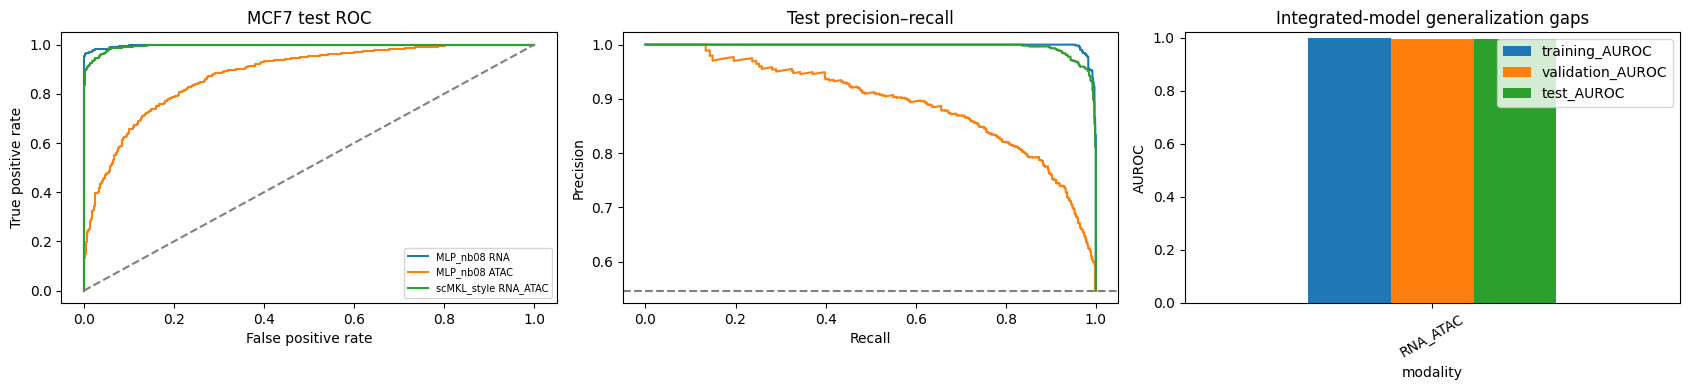

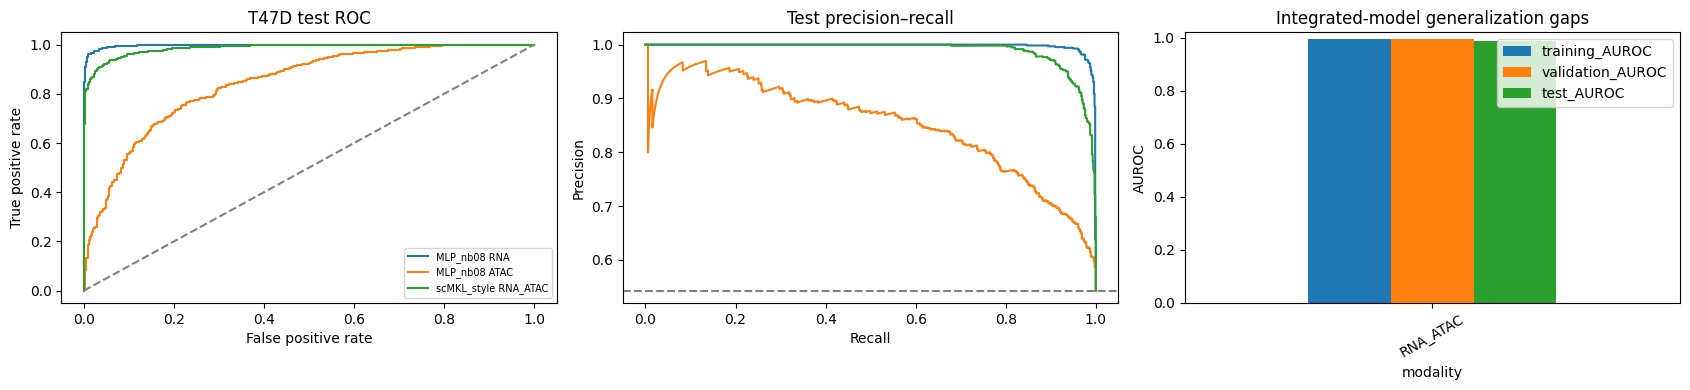

In [6]:
performance_plots(METRICS,GAPS,PREDICTIONS,OUTPUT)

## Selected pathways and motifs
Review all model weights, inspect integrated-model selection, and retain aliases for identical kernel
memberships. Plots show representative groups only, avoiding duplicate motif labels.
Coefficient magnitudes are not percentages of biological contribution or direct evidence of regulation.


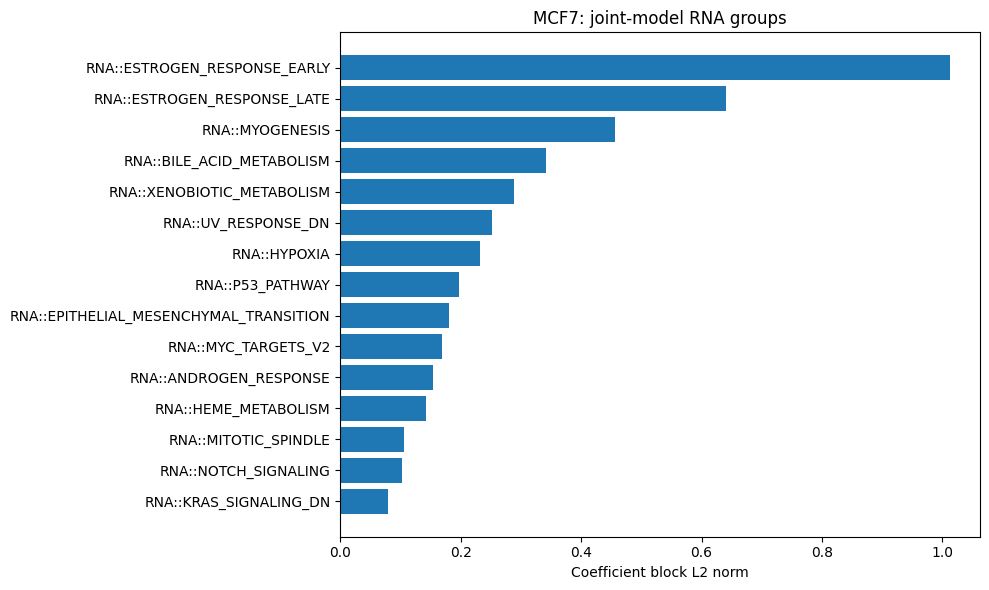

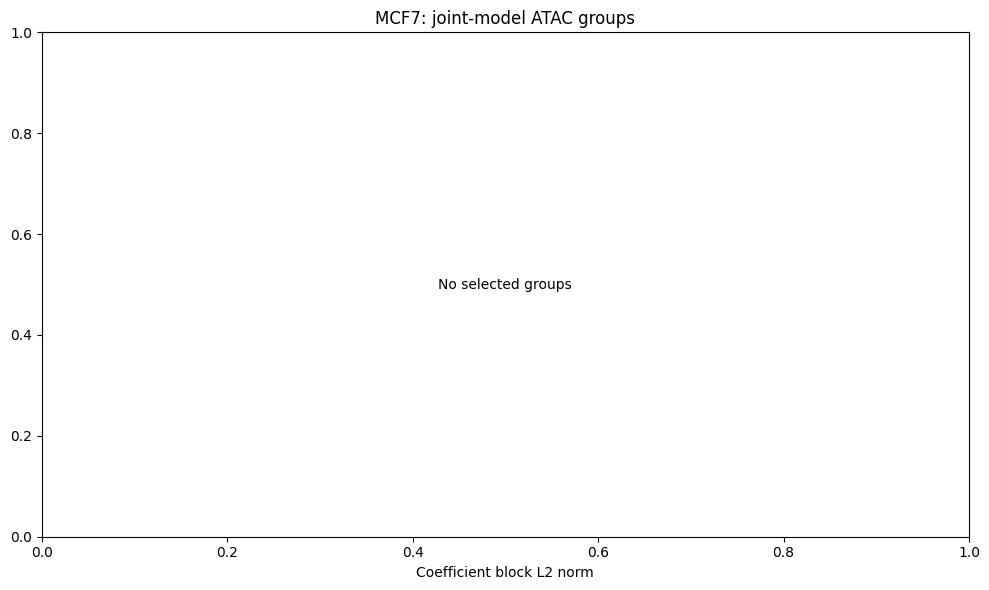

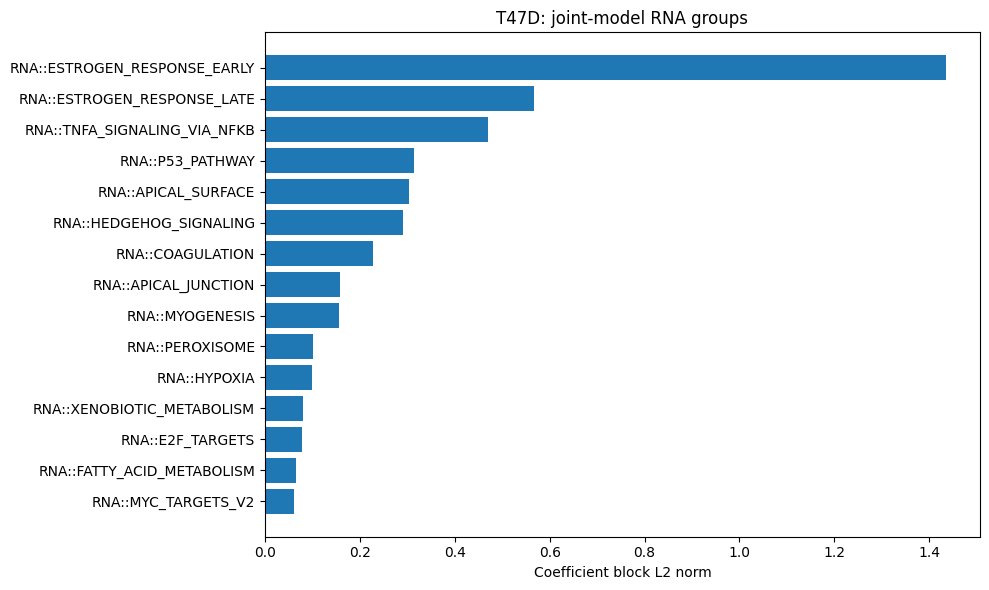

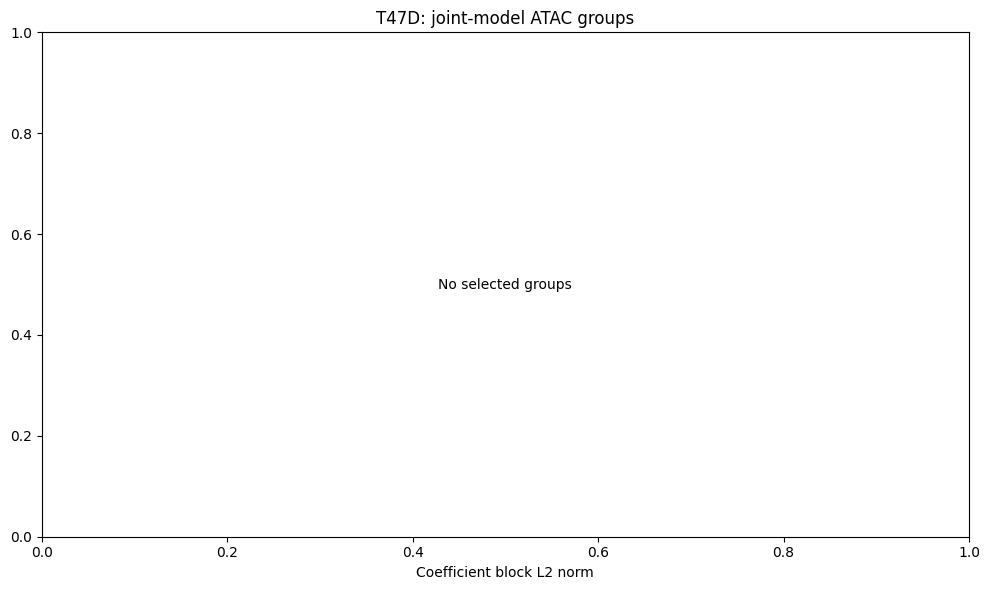

,group,modality,feature_count,sigma,rff_scale,map_file,coefficient_group_norm,selected,cell_line,input_mode
12,RNA::HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,89,13.184678,0.617932,group_0012.npz,1.011913,True,MCF7,RNA_ATAC
13,RNA::HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,81,12.522110,0.618899,group_0013.npz,0.641220,True,MCF7,RNA_ATAC
15,RNA::HALLMARK_MYOGENESIS,RNA,41,8.833231,0.630862,group_0015.npz,0.456089,True,MCF7,RNA_ATAC
43,RNA::HALLMARK_BILE_ACID_METABOLISM,RNA,29,7.490557,0.627804,group_0043.npz,0.341412,True,MCF7,RNA_ATAC
31,RNA::HALLMARK_XENOBIOTIC_METABOLISM,RNA,51,9.921389,0.625808,group_0031.npz,0.288480,True,MCF7,RNA_ATAC
38,RNA::HALLMARK_UV_RESPONSE_DN,RNA,73,11.780362,0.637038,group_0038.npz,0.251636,True,MCF7,RNA_ATAC
1,RNA::HALLMARK_HYPOXIA,RNA,50,9.838343,0.625043,group_0001.npz,0.231181,True,MCF7,RNA_ATAC
36,RNA::HALLMARK_P53_PATHWAY,RNA,72,11.702459,0.635999,group_0036.npz,0.196483,True,MCF7,RNA_ATAC
29,RNA::HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,RNA,30,7.409650,0.642994,group_0029.npz,0.180958,True,MCF7,RNA_ATAC
28,RNA::HALLMARK_MYC_TARGETS_V2,RNA,16,5.395315,0.646448,group_0028.npz,0.169193,True,MCF7,RNA_ATAC


,group,norm_MCF7,selected_MCF7,norm_T47D,selected_T47D,represented_MCF7,represented_T47D
0,ATAC::MA0002.3__Runx1,0.0,False,0.0,False,True,True
1,ATAC::MA0003.5__TFAP2A,0.0,False,0.0,False,True,True
2,ATAC::MA0004.1__Arnt,0.0,False,0.0,False,True,True
3,ATAC::MA0006.2__Ahr::Arnt,0.0,False,0.0,False,True,True
4,ATAC::MA0007.4__Ar,0.0,False,0.0,False,True,True
5,ATAC::MA0009.2__TBXT,0.0,False,0.0,False,True,True
6,ATAC::MA0014.4__PAX5,0.0,False,0.0,False,True,True
7,ATAC::MA0017.3__NR2F1,0.0,False,0.0,False,True,True
8,ATAC::MA0018.5__CREB1,0.0,False,0.0,False,True,True
9,ATAC::MA0019.2__Ddit3::Cebpa,0.0,False,0.0,False,True,True


In [7]:
WEIGHTS, ALIASES, CROSS_LINE = review_groups(SOURCE,OUTPUT,INPUTS)
display(WEIGHTS[(WEIGHTS.input_mode=="RNA_ATAC") & WEIGHTS.selected]
        .sort_values(["cell_line","modality","coefficient_group_norm"],ascending=[True,True,False]))
display(CROSS_LINE.head(20))


## Relate predictive groups to earlier biology
Optional context is joined by exact Hallmark names and JASPAR motif IDs.
All scenarios are preserved in exported tables. A selected group with no matching context is not
evidence of biological absence; inspect coverage and resource versions. Earlier analyses do not
feed back into model fitting or selection.


In [8]:
CONTEXT_STATUS = biological_context(BASE,OUTPUT,INPUTS,ALIASES)
display(CONTEXT_STATUS)
print("Context tables saved under:",OUTPUT)


,file,status
0,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted
1,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted
2,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted
3,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted
4,/content/drive/MyDrive/breast-cancer-multiome-...,missing_optional_not_interpreted


Context tables saved under: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb10/20261012T173135_214046Z


## Generate the review report and export
The report summarizes verified metrics, integration differences and selected groups, with limitations.
It does not automatically recommend tuning a model based on its test score.

**Send back the results ZIP** or comparison_report.md with the figures.
Possible next experiments are predefined repeated splits and cross-cell-line transfer; neither is
performed in this notebook.


In [9]:
RESULTS_ZIP = export_review(BASE,SOURCE,OUTPUT,INPUTS,METRICS,GAPS,DIFFERENCES,WEIGHTS,CONTEXT_STATUS)
from IPython.display import Markdown
display(Markdown((OUTPUT/"comparison_report.md").read_text()))


Report: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb10/20261012T173135_214046Z/comparison_report.md
Results archive: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/exports/nb10_20261012T173135_214046Z.zip


# nb10 model comparison and interpretation

Reviewed nb09 run: 20261012T114858_335840Z

This report uses saved predictions and coefficients only. No models were fitted or tuned.

## Test performance

| Cell line | Model | Inputs | AUROC | Average precision | Balanced accuracy | Errors |
|---|---|---|---:|---:|---:|---:|
| MCF7 | MLP_nb08 | RNA | 0.9981 | 0.9985 | 0.9775 | 28 |
| MCF7 | MLP_nb08 | ATAC | 0.8786 | 0.8944 | 0.7959 | 243 |
| MCF7 | scMKL_style | RNA_ATAC | 0.9954 | 0.9963 | 0.9590 | 49 |
| T47D | MLP_nb08 | RNA | 0.9969 | 0.9977 | 0.9734 | 34 |
| T47D | MLP_nb08 | ATAC | 0.8438 | 0.8522 | 0.7519 | 315 |
| T47D | scMKL_style | RNA_ATAC | 0.9863 | 0.9894 | 0.9388 | 81 |

## Descriptive integration differences

- MCF7, joint versus MLP_nb08_RNA: AUROC difference -0.00269; AP difference -0.00222; 11 errors corrected and 32 new errors.
- MCF7, joint versus MLP_nb08_ATAC: AUROC difference +0.11676; AP difference +0.10193; 225 errors corrected and 31 new errors.
- T47D, joint versus MLP_nb08_RNA: AUROC difference -0.01066; AP difference -0.00833; 15 errors corrected and 62 new errors.
- T47D, joint versus MLP_nb08_ATAC: AUROC difference +0.14250; AP difference +0.13717; 287 errors corrected and 53 new errors.

These are single-split point differences, not significance tests or estimates of biological-replicate uncertainty.

## Selected groups

- MCF7 RNA: 27 selected representative groups. Highest coefficient norms: RNA::HALLMARK_ESTROGEN_RESPONSE_EARLY, RNA::HALLMARK_ESTROGEN_RESPONSE_LATE, RNA::HALLMARK_MYOGENESIS, RNA::HALLMARK_BILE_ACID_METABOLISM, RNA::HALLMARK_XENOBIOTIC_METABOLISM.
- MCF7 ATAC: 0 selected representative groups. Highest coefficient norms: none.
- T47D RNA: 22 selected representative groups. Highest coefficient norms: RNA::HALLMARK_ESTROGEN_RESPONSE_EARLY, RNA::HALLMARK_ESTROGEN_RESPONSE_LATE, RNA::HALLMARK_TNFA_SIGNALING_VIA_NFKB, RNA::HALLMARK_P53_PATHWAY, RNA::HALLMARK_APICAL_SURFACE.
- T47D ATAC: 0 selected representative groups. Highest coefficient norms: none.

## Interpretation limits

- Group norms are unsigned predictive weights, not activation, repression or causal importance.
- Aliases sharing a kernel are not independent selected TFs/pathways.
- Earlier GSEA/ATAC/motif outputs use this same cohort and provide descriptive context, not independent validation.
- Missing groups reflect coverage or filtering; missing context files are not negative biological evidence.
- All nb07 matching-QC flags, directions and coordinate scenarios are retained.
- Cross-line overlap is descriptive and does not measure repeat-split stability or transfer performance.
- Test scores have already been inspected; any test-guided tuning requires independent confirmation.
- Biological replicate IDs are unavailable, and treatment/library confounding remains possible.
- No confidence intervals, significance tests, retraining or cross-line transfer were performed.

## Next decisions

Review whether joint kernels improve over the RNA and ATAC MLP baselines; inspect solver status and validation/test gaps before interpreting small differences. Compare selected groups with all available biological context, preserving negative NES and failed matching flags. Use predefined additional splits or independent data for robustness; do not tune on this report.

Optional biological-context files available: 0/5.


### Optional download
The archive is already saved in Drive. Set the switch below to download it.

In [10]:
DOWNLOAD_RESULTS=False
if DOWNLOAD_RESULTS and IN_COLAB:
    from google.colab import files
    files.download(str(RESULTS_ZIP))
